In [3]:
import kagglehub
from pathlib import Path
import random
import os
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pprint import pprint as p

In [4]:
path = kagglehub.dataset_download("ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes")
DATA_DIR  = Path(path)
ARTIFACT_DIR = Path.cwd() / "workspace" / "artifacts" 
CLASSES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

Using Colab cache for faster access to the 'mri-for-brain-tumor-with-bounding-boxes' dataset.


In [5]:
def count_files_by_split_and_class(root_path: Path) -> dict:
    existing_class = {
        "Train": {class_name: 0 for class_name in CLASSES},
        "Val": {class_name: 0 for class_name in CLASSES},
    }

    if not root_path.is_dir():
        raise NotADirectoryError(f"Dataset directory not found: {root_path}")

    for file_path in root_path.rglob("*"):
        if not file_path.is_file() or file_path.suffix.lower() not in extensions:
            continue

        relative_parts = file_path.relative_to(root_path).parts
        normalized_parts = [part.lower() for part in relative_parts]

        split = next(
            (name for name in ("Train", "Val") if name.lower() in normalized_parts),
            None,
        )
        class_name = next(
            (name for name in CLASSES if name.lower() in normalized_parts),
            None,
        )

        if split and class_name:
            existing_class[split][class_name] += 1

    return existing_class


existing_class = count_files_by_split_and_class(DATA_DIR)
p(existing_class)

{'Train': {'Glioma': 1153,
           'Meningioma': 1449,
           'No Tumor': 711,
           'Pituitary': 1424},
 'Val': {'Glioma': 136, 'Meningioma': 140, 'No Tumor': 100, 'Pituitary': 136}}


In [6]:
def show_tree(root: Path, max_depth: int = 3, sample_files: int = 5):
    for current_dir, directories, files in os.walk(root):
        current_path = Path(current_dir)
        relative_path = current_path.relative_to(root)
        depth = len(relative_path.parts)

        if depth > max_depth:
            directories[:] = []
            continue

        indent = "    " * depth
        folder_name = root.name if depth == 0 else current_path.name
        print(f"{indent}📁 {folder_name}/")

        for filename in sorted(files)[:sample_files]:
            print(f"{indent}    📄 {filename}")

        remaining = len(files) - sample_files
        if remaining > 0:
            print(f"{indent}    ... {remaining} more files")


show_tree(DATA_DIR)

📁 mri-for-brain-tumor-with-bounding-boxes/
    📁 Val/
        📁 Pituitary/
            📁 labels/
                📄 Te-pi_0018.txt
                📄 Te-pi_0021.txt
                📄 Te-pi_0025.txt
                📄 Te-pi_0036.txt
                📄 Te-pi_0041.txt
                ... 131 more files
            📁 images/
                📄 Te-pi_0018.jpg
                📄 Te-pi_0021.jpg
                📄 Te-pi_0025.jpg
                📄 Te-pi_0036.jpg
                📄 Te-pi_0041.jpg
                ... 131 more files
        📁 No Tumor/
            📁 labels/
                📄 Tr-no_0025.txt
                📄 Tr-no_0042.txt
                📄 Tr-no_0048.txt
                📄 Tr-no_0049.txt
                📄 Tr-no_0058.txt
                ... 95 more files
            📁 images/
                📄 Tr-no_0025.jpg
                📄 Tr-no_0042.jpg
                📄 Tr-no_0048.jpg
                📄 Tr-no_0049.jpg
                📄 Tr-no_0058.jpg
                ... 95 more files
        📁 Meningiom

In [7]:
def inspect_label_samples(
    root_path: Path,
    split: str = "Train",
    samples_per_class: int = 3,
):
    for class_name in CLASSES:
        labels_dir = root_path / split / class_name / "labels"
        label_paths = sorted(labels_dir.glob("*.txt"))

        print(f"\n{class_name}: {len(label_paths)} label files")

        for label_path in label_paths[:samples_per_class]:
            content = label_path.read_text(encoding="utf-8").strip()
            displayed_content = content if content else "<EMPTY>"
            print(f"  {label_path.name}: {displayed_content}")


inspect_label_samples(DATA_DIR)


Glioma: 1153 label files
  Te-glTr_0000.txt: 0 0.555664 0.653320 0.146484 0.193359
  Te-glTr_0005.txt: 0 0.587891 0.320312 0.144531 0.144531
  Te-glTr_0007.txt: 0 0.499023 0.573242 0.099609 0.107422

Meningioma: 1449 label files
  Tr-meTr_0008.txt: 1 0.313477 0.631836 0.193359 0.240234
  Tr-meTr_0009.txt: 1 0.625000 0.488281 0.210938 0.195312
  Tr-me_0010.txt: 1 0.321289 0.615234 0.197266 0.269531

No Tumor: 711 label files
  1.txt: 2 0.502857 0.675714 0.851429 0.648571
  3.txt: 2 0.512397 0.513051 0.770248 0.973899
  4.txt: 2 0.525801 0.507601 0.809609 0.984797

Pituitary: 1424 label files
  Te-pi_0010.txt: 3 0.494141 0.431641 0.046875 0.039062
  Te-pi_0011.txt: 3 0.499023 0.382812 0.080078 0.074219
  Te-pi_0013.txt: 3 0.458984 0.401367 0.058594 0.056641


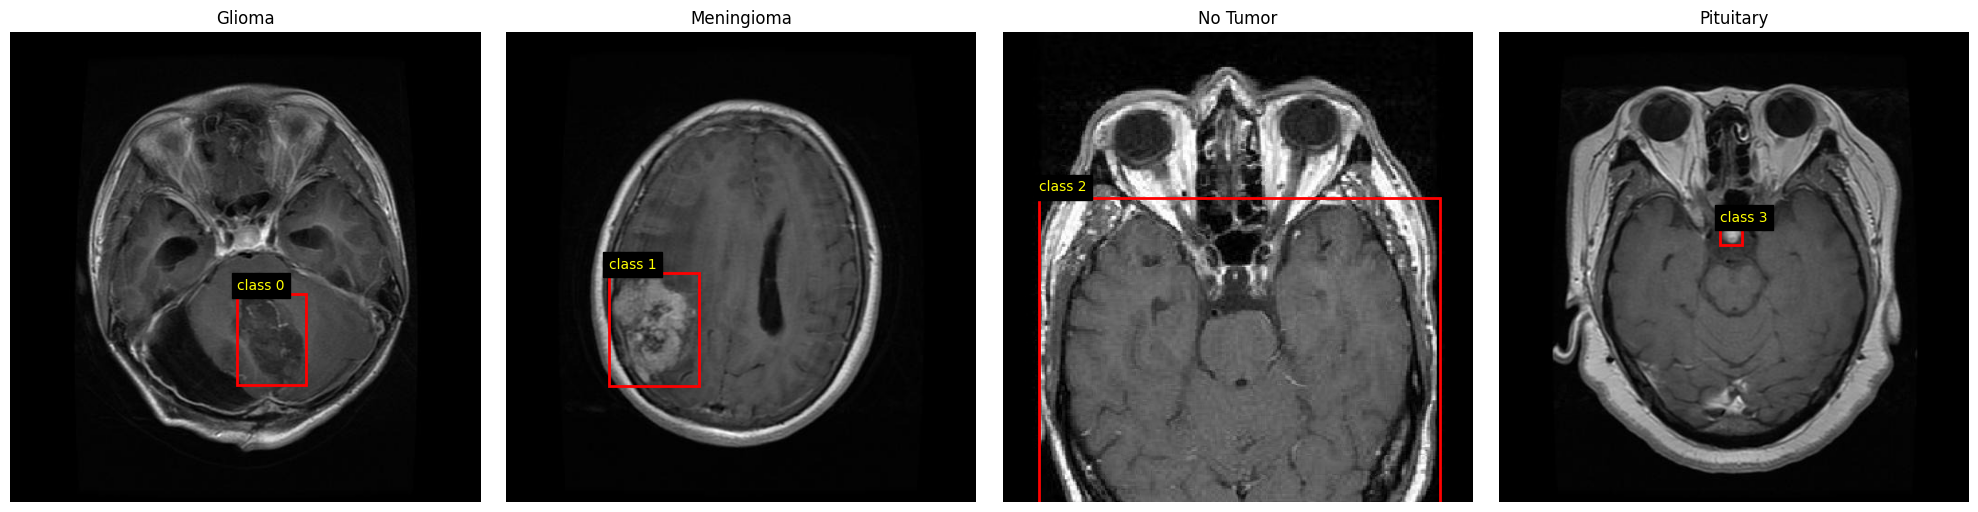

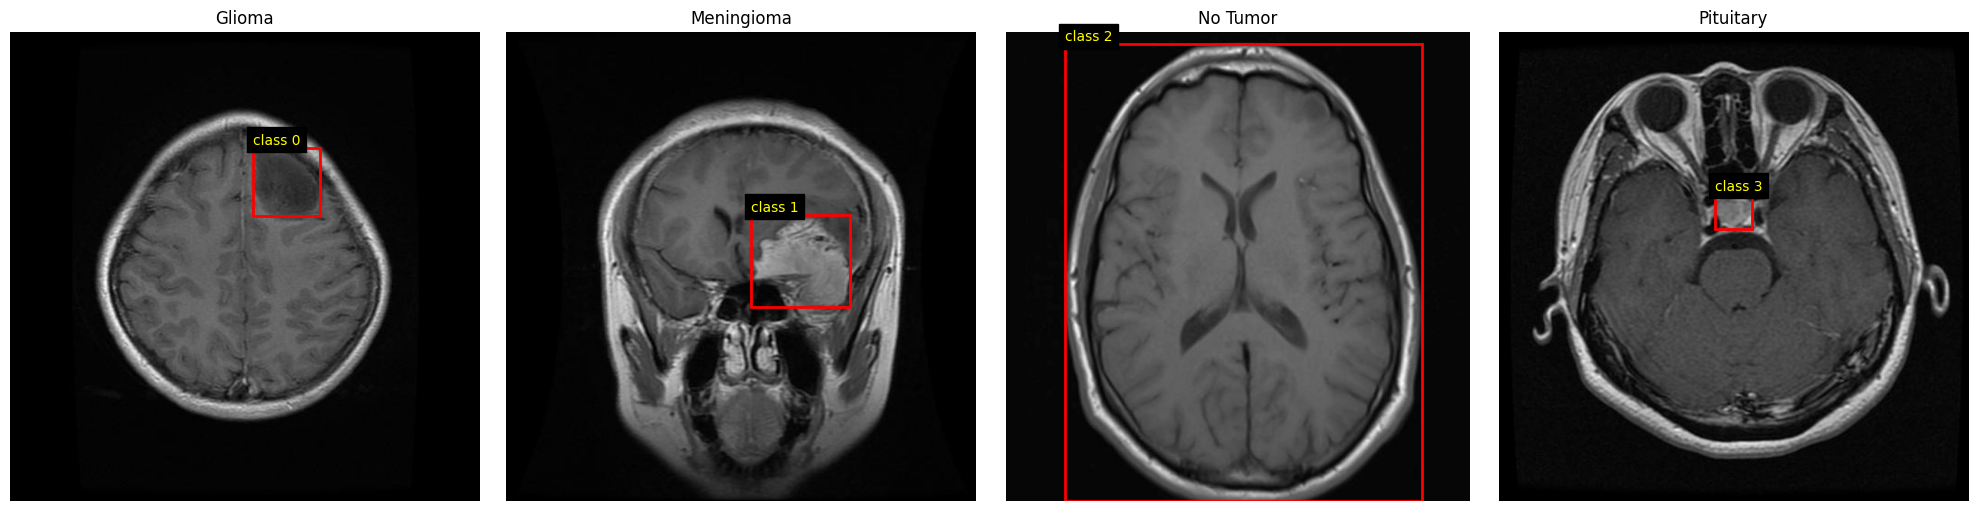

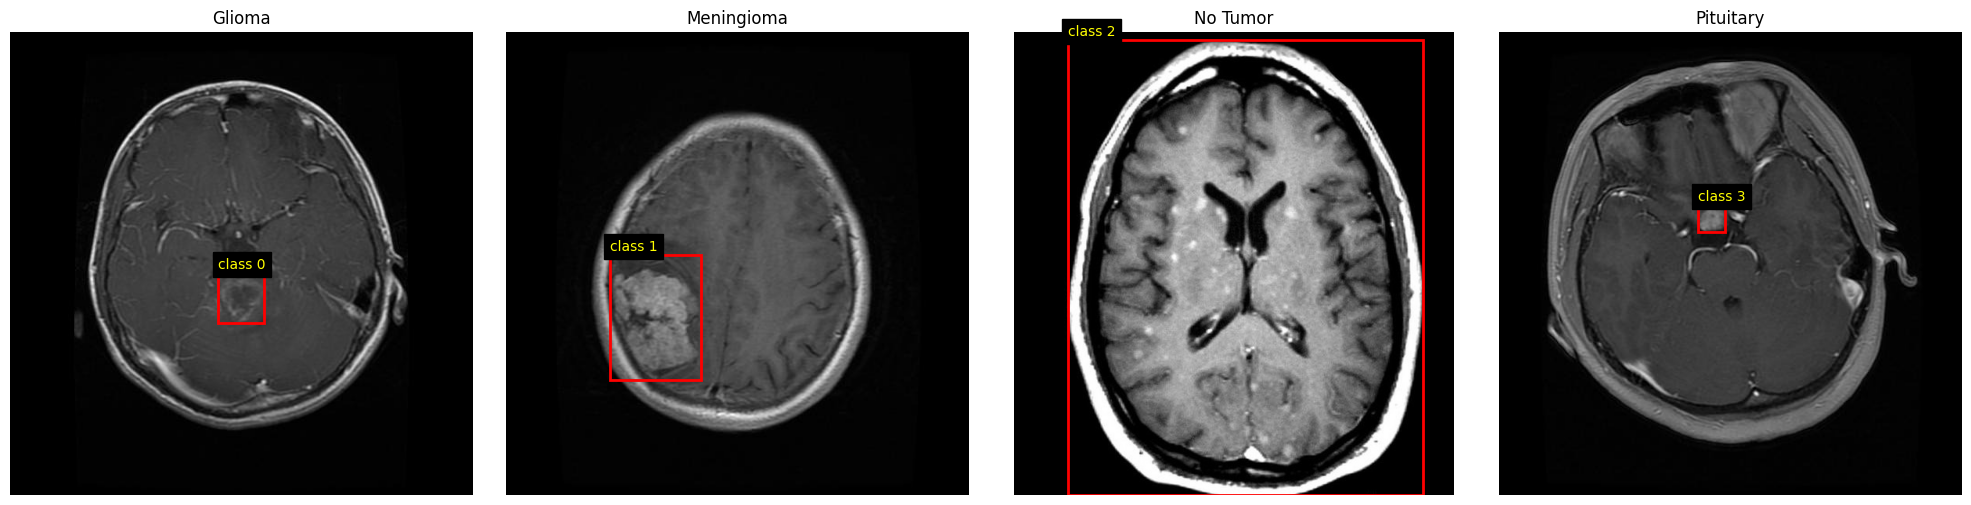

In [8]:
def show_one_sample_per_class(root_path: Path, split: str = "Train", sample_index: int = 0):
    fig, axes = plt.subplots(1, len(CLASSES), figsize=(20, 5))

    for axis, folder_class in zip(axes, CLASSES):
        images_dir = root_path / split / folder_class / "images"
        labels_dir = root_path / split / folder_class / "labels"

        image_paths = sorted(
            path for path in images_dir.iterdir()
            if path.suffix.lower() in extensions
        )

        image_path = image_paths[sample_index]
        label_path = labels_dir / f"{image_path.stem}.txt"

        image_bgr = cv2.imread(str(image_path))
        if image_bgr is None:
            raise ValueError(f"Unreadable image: {image_path}")

        image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        image_height, image_width = image.shape[:2]

        axis.imshow(image)
        axis.set_title(folder_class)
        axis.axis("off")

        label_lines = label_path.read_text().strip().splitlines()

        for line in label_lines:
            class_id, xc, yc, box_width, box_height = map(
                float, line.split()
            )

            x_min = (xc - box_width / 2) * image_width
            y_min = (yc - box_height / 2) * image_height
            pixel_width = box_width * image_width
            pixel_height = box_height * image_height

            rectangle = Rectangle(
                (x_min, y_min),
                pixel_width,
                pixel_height,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )
            axis.add_patch(rectangle)
            axis.text(
                x_min,
                max(0, y_min - 5),
                f"class {int(class_id)}",
                color="yellow",
                fontsize=10,
                backgroundcolor="black",
            )

    plt.tight_layout()
    # plt.savefig(ARTIFACT_DIR)
    plt.show()


# Three calls reuse the same drawing function and show 12 images in total.
for sample_index in range(3):
    show_one_sample_per_class(DATA_DIR, sample_index=sample_index)

# 1. EDA: the remaining checks

The cells above already download the dataset, count images, inspect the
tree and sample labels, and draw 12 MRIs. Here we check file quality,
all annotations, class balance, and leakage. These cells read the raw
Kaggle dataset without changing it.

From the earlier saved run: Val/No Tumor had 2 images without matching
labels and 2 orphan labels. OpenCV found 0 unreadable images. There
were 213 groups of identical images across Train and Val. The earlier
report of 279 invalid rows was too high because it treated every class
different from the folder name as an error; an MRI may have multiple
tumor classes. The corrected check below reports those separately.

## 1.1 Image and label pairs

Equal numbers of images and labels do not prove that names match.
We compare filename stems, count unsupported files, and ask OpenCV
to decode every supported image. We print a few examples of each
problem so they can be investigated before cleaning.

In [9]:
splits = ("Train", "Val")
pair_results = []
all_images = []

for split in splits:
    for class_name in CLASSES:
        images_dir = DATA_DIR / split / class_name / "images"
        labels_dir = DATA_DIR / split / class_name / "labels"

        files = [path for path in images_dir.iterdir() if path.is_file()]
        images = [
            path for path in files
            if path.suffix.lower() in extensions
        ]
        labels = list(labels_dir.glob("*.txt"))

        image_stems = {path.stem for path in images}
        label_stems = {path.stem for path in labels}
        missing = image_stems - label_stems
        orphan = label_stems - image_stems
        broken = []

        for image_path in images:
            # OpenCV returns None for most unreadable images.
            try:
                image = cv2.imread(str(image_path))
            except cv2.error:
                image = None
            if image is None:
                broken.append(image_path.name)
            all_images.append((split, class_name, image_path))

        result = {
            "split": split,
            "class": class_name,
            "images": len(images),
            "labels": len(labels),
            "missing": len(missing),
            "orphan": len(orphan),
            "unsupported": len(files) - len(images),
            "broken": len(broken),
            "duplicate_stems": len(images) - len(image_stems),
        }
        pair_results.append(result)
        print(result)

        if missing:
            print("  Images without labels:", sorted(missing)[:5])
        if orphan:
            print("  Labels without images:", sorted(orphan)[:5])
        if broken:
            print("  Unreadable images:", broken[:5])

{'split': 'Train', 'class': 'Glioma', 'images': 1153, 'labels': 1153, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Train', 'class': 'Meningioma', 'images': 1449, 'labels': 1449, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Train', 'class': 'No Tumor', 'images': 711, 'labels': 711, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Train', 'class': 'Pituitary', 'images': 1424, 'labels': 1424, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Val', 'class': 'Glioma', 'images': 136, 'labels': 136, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Val', 'class': 'Meningioma', 'images': 140, 'labels': 140, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Val', 'class': 'No Tumor', 'images': 100, 'labels': 100, 'missing': 2, 'orphan': 2, 'u

## 1.2 Check every YOLO annotation

Each non-empty line needs five values: class ID, center x/y, width,
and height. The box must have positive size and stay inside the image.
We count boxes by the ID written in the label. If that ID differs from
the folder name, we report it for review but do not automatically
call it invalid.

In [10]:
import math
from collections import Counter

source_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}
expected_id = {name: class_id for class_id, name in source_names.items()}
box_counts = {split: Counter() for split in splits}
box_areas = {class_id: [] for class_id in source_names}
empty_labels = Counter()
folder_mismatch = Counter()
bad_labels = []

for split in splits:
    for folder_class in CLASSES:
        labels_dir = DATA_DIR / split / folder_class / "labels"

        for label_path in labels_dir.glob("*.txt"):
            try:
                content = label_path.read_text(encoding="utf-8").strip()
            except (OSError, UnicodeError) as error:
                bad_labels.append((str(label_path), 0, str(error)))
                continue

            if not content:
                empty_labels[(split, folder_class)] += 1
                continue

            for line_number, line in enumerate(content.splitlines(), 1):
                parts = line.split()
                if len(parts) != 5:
                    bad_labels.append((str(label_path), line_number, "Expected 5 values"))
                    continue

                try:
                    class_id = int(parts[0])
                    x, y, width, height = map(float, parts[1:])
                except ValueError:
                    bad_labels.append((str(label_path), line_number, "Invalid number"))
                    continue

                values = (x, y, width, height)
                box_inside = (
                    x - width / 2 >= -1e-6
                    and x + width / 2 <= 1 + 1e-6
                    and y - height / 2 >= -1e-6
                    and y + height / 2 <= 1 + 1e-6
                )
                valid = (
                    class_id in source_names
                    and all(math.isfinite(value) for value in values)
                    and all(0 <= value <= 1 for value in values)
                    and width > 0 and height > 0
                    and box_inside
                )

                if not valid:
                    bad_labels.append((str(label_path), line_number, "Invalid class or box"))
                    continue

                box_counts[split][class_id] += 1
                box_areas[class_id].append(width * height)

                if class_id != expected_id[folder_class]:
                    folder_mismatch[(split, folder_class, class_id)] += 1

for split in splits:
    print(split, "boxes:", {
        source_names[class_id]: box_counts[split][class_id]
        for class_id in source_names
    })
    print(split, "empty labels:", {
        name: empty_labels[(split, name)] for name in CLASSES
    })

print("Invalid label lines:", len(bad_labels))
print("Valid boxes with a class different from their folder:")
for key, count in folder_mismatch.items():
    print(" ", key, count)
for problem in bad_labels[:10]:
    print("  Invalid:", problem)

Train boxes: {'Glioma': 1349, 'Meningioma': 1482, 'No Tumor': 711, 'Pituitary': 1775}
Train empty labels: {'Glioma': 0, 'Meningioma': 0, 'No Tumor': 0, 'Pituitary': 0}
Val boxes: {'Glioma': 153, 'Meningioma': 142, 'No Tumor': 100, 'Pituitary': 161}
Val empty labels: {'Glioma': 1, 'Meningioma': 0, 'No Tumor': 0, 'Pituitary': 0}
Invalid label lines: 0
Valid boxes with a class different from their folder:
  ('Train', 'Glioma', 3) 152
  ('Train', 'Glioma', 1) 3
  ('Train', 'Meningioma', 3) 103
  ('Train', 'Meningioma', 0) 2
  ('Train', 'Pituitary', 1) 1
  ('Val', 'Glioma', 3) 12
  ('Val', 'Meningioma', 3) 6


## 1.3 Images, boxes, and box sizes

An image can contain several boxes. The first two plots compare
image counts with the actual class IDs in label files. The last plot
shows normalized box area (width times height); the observed No Tumor
boxes are large because they surround the brain.

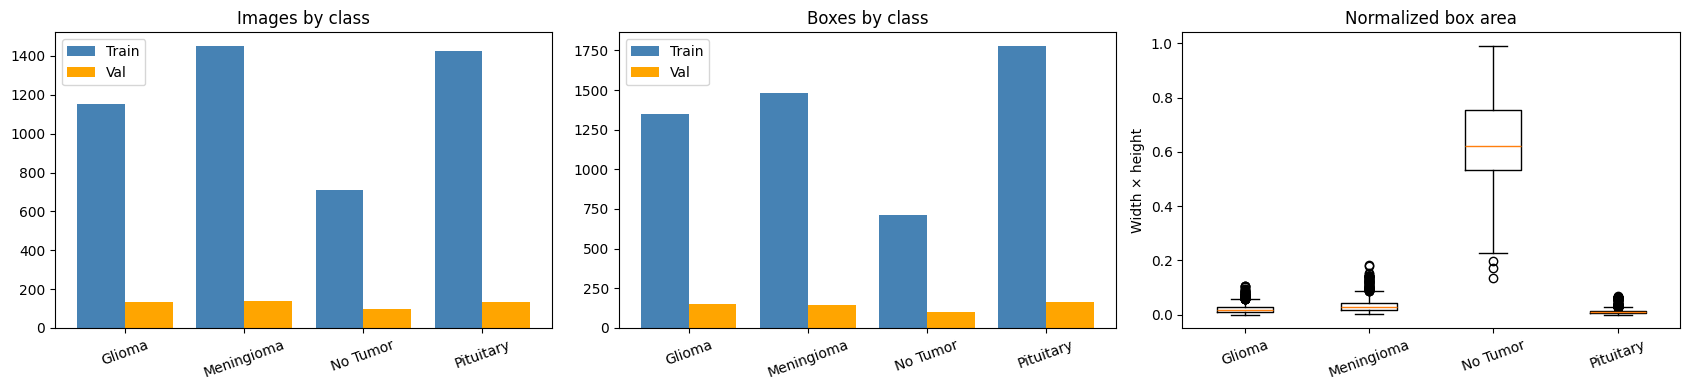

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
positions = list(range(len(CLASSES)))

for axis, counts, title in (
    (axes[0], existing_class, "Images"),
    (axes[1], box_counts, "Boxes"),
):
    for offset, split, color in (
        (-0.2, "Train", "steelblue"),
        (0.2, "Val", "orange"),
    ):
        if title == "Images":
            values = [counts[split][name] for name in CLASSES]
        else:
            values = [counts[split][class_id] for class_id in source_names]
        axis.bar(
            [i + offset for i in positions], values,
            width=0.4, label=split, color=color,
        )
    axis.set_xticks(positions, CLASSES, rotation=20)
    axis.set_title(title + " by class")
    axis.legend()

axes[2].boxplot([box_areas[class_id] for class_id in source_names])
axes[2].set_xticks([1, 2, 3, 4], CLASSES, rotation=20)
axes[2].set_title("Normalized box area")
axes[2].set_ylabel("Width × height")

plt.tight_layout()
plt.show()

## 1.4 Exact duplicates across splits

Identical files have the same SHA-256 hash even if their names differ.
A copy in both Train and Val makes validation results unreliable.
This check finds exact byte-for-byte copies. It cannot find resized
copies or prove that different images come from different patients.

In [12]:
import hashlib

images_by_hash = {}
splits_by_stem = {}

for split, class_name, image_path in all_images:
    # Only one image is held in memory at a time.
    image_hash = hashlib.sha256(image_path.read_bytes()).hexdigest()
    images_by_hash.setdefault(image_hash, []).append(
        (split, class_name, image_path.name)
    )
    splits_by_stem.setdefault(image_path.stem, set()).add(split)

duplicate_groups = [
    group for group in images_by_hash.values() if len(group) > 1
]
cross_split_groups = [
    group for group in duplicate_groups
    if len({item[0] for item in group}) > 1
]
conflicting_folders = [
    group for group in duplicate_groups
    if len({item[1] for item in group}) > 1
]
shared_stems = [
    stem for stem, found_splits in splits_by_stem.items()
    if len(found_splits) > 1
]

print("Exact duplicate groups:", len(duplicate_groups))
print("Exact groups crossing Train/Val:", len(cross_split_groups))
print("Exact groups in different class folders:", len(conflicting_folders))
print("Filename stems in both splits:", len(shared_stems))
for group in cross_split_groups[:5]:
    print("  Cross-split duplicate:", group)

Exact duplicate groups: 1228
Exact groups crossing Train/Val: 213
Exact groups in different class folders: 0
Filename stems in both splits: 0
  Cross-split duplicate: [('Train', 'Glioma', 'gg (104).jpg'), ('Val', 'Glioma', 'gg (86).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'Tr-gl_0010.jpg'), ('Val', 'Glioma', 'gg (312).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'Tr-gl_0065.jpg'), ('Val', 'Glioma', 'gg (532).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'Tr-gl_0020.jpg'), ('Val', 'Glioma', 'gg (352).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'Tr-gl_0024.jpg'), ('Val', 'Glioma', 'gg (368).jpg')]


# 2. Preprocessing
Format reference: [Ultralytics detection datasets](https://docs.ultralytics.com/datasets/detect/).
For example, source `3 0.5 0.4 0.1 0.2` becomes
`2 0.5 0.4 0.1 0.2`: the class changes; the box stays the same.

### 2.1 Settings and label conversion

In [13]:
import csv
import json
import shutil
import hashlib
import math
from collections import Counter

SEED = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

# Use the project root whether Jupyter starts here or in notebooks/.
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == 'notebooks':
    PROJECT_DIR = PROJECT_DIR.parent
PROCESSED_DIR = (PROJECT_DIR / 'data' / 'processed' / 'neurovision_v1').resolve()

new_names = {0: 'Glioma', 1: 'Meningioma', 2: 'Pituitary'}
class_mapping = {0: 0, 1: 1, 3: 2}
folder_ids = {'Glioma': 0, 'Meningioma': 1, 'No Tumor': 2, 'Pituitary': 3}

def prepare_label(label_path, folder_class):
    # Return converted lines and a reason if the image needs review.
    if not label_path.is_file():
        return [], 'Missing label'
    try:
        content = label_path.read_text(encoding='utf-8').strip()
    except (OSError, UnicodeError):
        return [], 'Unreadable label'
    if not content and folder_class != 'No Tumor':
        return [], 'Empty label in a tumor folder'

    converted = []
    for line in content.splitlines():
        parts = line.split()
        if len(parts) != 5:
            return [], 'Expected five label values'
        try:
            class_id = int(parts[0])
            x, y, width, height = map(float, parts[1:])
        except ValueError:
            return [], 'Invalid number in label'
        values = (x, y, width, height)
        if not all(math.isfinite(v) and 0 <= v <= 1 for v in values):
            return [], 'Coordinates must be finite and between 0 and 1'
        if width <= 0 or height <= 0:
            return [], 'Box has zero or negative size'
        if (x - width / 2 < -1e-6 or x + width / 2 > 1 + 1e-6
                or y - height / 2 < -1e-6 or y + height / 2 > 1 + 1e-6):
            return [], 'Box crosses image boundary'
        if class_id != folder_ids[folder_class]:
            return [], 'Folder/class mismatch: requires annotation review'
        if class_id != 2:
            # Preserve normalized coordinates, including every box.
            converted.append((class_mapping[class_id], x, y, width, height))

    # Sorting lets us compare duplicate labels regardless of row order.
    return sorted(converted), ''

assert 0 < TRAIN_RATIO < 1 and 0 < VAL_RATIO < 1 - TRAIN_RATIO
assert DATA_DIR.resolve() != PROCESSED_DIR
assert DATA_DIR.resolve() not in PROCESSED_DIR.parents
print('Output:', PROCESSED_DIR)


Output: /content/data/processed/neurovision_v1


### 2.2 Build the processing list

We need a record for every source image, including rejected ones.
The pixel hash identifies duplicates; a review reason explains why
an image is withheld. Orphan labels are logged separately.
No files are copied in this cell.

In [14]:
def pixel_hash(image):
    # Shape is included: equal bytes with different dimensions differ.
    digest = hashlib.sha256(str(image.shape).encode())
    digest.update(image.tobytes())
    return digest.hexdigest()

records = []
orphan_labels = []

for source_split in ('Train', 'Val'):
    for folder_class in CLASSES:
        folder = DATA_DIR / source_split / folder_class
        assert (folder / 'images').is_dir(), f'Missing images directory: {folder}'
        assert (folder / 'labels').is_dir(), f'Missing labels directory: {folder}'
        image_paths = []
        for path in sorted((folder / 'images').iterdir()):
            if path.is_file() and path.suffix.lower() in extensions:
                image_paths.append(path)
        stems = Counter(path.stem for path in image_paths)

        for label_path in sorted((folder / 'labels').glob('*.txt')):
            if label_path.stem not in stems:
                orphan_labels.append(str(label_path))

        for image_path in image_paths:
            label_path = folder / 'labels' / (image_path.stem + '.txt')
            boxes, reason = prepare_label(label_path, folder_class)
            try:
                image = cv2.imread(str(image_path))
            except cv2.error:
                image = None
            image_hash = ''
            if image is None:
                reason = 'Unreadable image'
            else:
                image_hash = pixel_hash(image)
            if stems[image_path.stem] > 1:
                reason = 'Multiple images share the same label stem'
            records.append({
                'source_split': source_split,
                'folder': folder_class,
                'image': image_path,
                'label': label_path,
                'hash': image_hash,
                'boxes': boxes,
                'reason': reason,
                'status': 'review' if reason else 'pending',
                'new_split': '',
                'destination': '',
            })

assert records, 'No source images found; check DATA_DIR.'
print('Source images:', len(records))
print('Orphan labels:', len(orphan_labels))
print('Initial review reasons:', Counter(r['reason'] for r in records if r['reason']))


Source images: 5249
Orphan labels: 2
Initial review reasons: Counter({'Folder/class mismatch: requires annotation review': 272, 'Missing label': 2, 'Empty label in a tumor folder': 1})


### 2.3 Resolve duplicates, then assign splits

An identical image must appear only once. If copies disagree about
their boxes or folder, or any copy needs review, withhold the whole
group. This conservative choice is recorded in the audit. Otherwise,
keep the first copy in a stable order.

Shuffle unique images separately per folder. With 100 unique Glioma
images, 70 go to train, 15 to val, and 15 to test. This preserves
approximately the same folder proportions without oversampling.

In [15]:
# Group every copy before shuffling images into new splits.
groups = {}
for record in records:
    if record['hash']:
        groups.setdefault(record['hash'], []).append(record)

unique_images = []
for image_hash in sorted(groups):
    group = groups[image_hash]
    first = group[0]
    needs_review = any(record['reason'] for record in group)
    disagreement = any(
        record['folder'] != first['folder'] or record['boxes'] != first['boxes']
        for record in group
    )
    if needs_review or disagreement:
        for record in group:
            record['status'] = 'review'
            if not record['reason']:
                record['reason'] = 'Duplicate group has conflicting or unresolved annotations'
        continue
    first['status'] = 'kept'
    unique_images.append(first)
    for record in group[1:]:
        record['status'] = 'duplicate'
        record['destination'] = str(first['image'])

# A local random generator makes the split independent of other cells.
rng = random.Random(SEED)
processed_splits = {'train': [], 'val': [], 'test': []}
for folder_class in CLASSES:
    images = [r for r in unique_images if r['folder'] == folder_class]
    rng.shuffle(images)
    train_end = int(len(images) * TRAIN_RATIO)
    val_end = train_end + int(len(images) * VAL_RATIO)
    assert 0 < train_end < val_end < len(images), f'Too few usable images: {folder_class}'
    processed_splits['train'].extend(images[:train_end])
    processed_splits['val'].extend(images[train_end:val_end])
    processed_splits['test'].extend(images[val_end:])

print('Decisions:', Counter(r['status'] for r in records))
for split, images in processed_splits.items():
    print(split, 'images by source folder:', dict(Counter(r['folder'] for r in images)))


Decisions: Counter({'kept': 2625, 'review': 2406, 'duplicate': 218})
train images by source folder: {'Glioma': 667, 'Meningioma': 396, 'No Tumor': 414, 'Pituitary': 359}
val images by source folder: {'Glioma': 143, 'Meningioma': 84, 'No Tumor': 88, 'Pituitary': 76}
test images by source folder: {'Glioma': 144, 'Meningioma': 86, 'No Tumor': 90, 'Pituitary': 78}


### 2.4 Write the YOLO dataset and reports

YOLO pairs `images/train/example.jpg` with `labels/train/example.txt`.
Use the full pixel hash as the filename to avoid name collisions.
Images are copied without changing their pixels. Every kept image
gets a label file, including an empty file for a negative.

The output folder must be new. To make another version, change
`neurovision_v1` in settings and rerun preprocessing in order.
`audit.csv` lists every source image and orphan label; `manifest.csv`
lists only exported pairs. Review files stay in the raw download.

In [16]:
if PROCESSED_DIR.exists():
    raise FileExistsError('Output already exists. Choose a new version in settings.')
PROCESSED_DIR.mkdir(parents=True)

manifest = []
for split, images in processed_splits.items():
    image_dir = PROCESSED_DIR / 'images' / split
    label_dir = PROCESSED_DIR / 'labels' / split
    image_dir.mkdir(parents=True)
    label_dir.mkdir(parents=True)
    for record in images:
        name = record['hash']
        image_path = image_dir / (name + record['image'].suffix.lower())
        label_path = label_dir / (name + '.txt')
        shutil.copy2(record['image'], image_path)
        lines = []
        for class_id, x, y, width, height in record['boxes']:
            lines.append(f'{class_id} {x} {y} {width} {height}')
        content = '\n'.join(lines)
        if lines:
            content += '\n'
        label_path.write_text(content, encoding='utf-8')
        record['new_split'] = split
        record['destination'] = image_path.relative_to(PROCESSED_DIR).as_posix()
        manifest.append({
            'split': split, 'folder': record['folder'],
            'source': str(record['image']), 'pixel_hash': name,
            'image': record['destination'],
            'label': label_path.relative_to(PROCESSED_DIR).as_posix(),
            'boxes': len(lines),
        })

# JSON quoting produces a valid YAML string even for paths with spaces.
yaml_text = 'path: ' + json.dumps(PROCESSED_DIR.as_posix()) + '\n'
yaml_text += 'train: images/train\nval: images/val\ntest: images/test\n'
yaml_text += 'names:\n  0: Glioma\n  1: Meningioma\n  2: Pituitary\n'
(PROCESSED_DIR / 'data.yaml').write_text(yaml_text, encoding='utf-8')

audit = []
for record in records:
    audit.append({
        'image': str(record['image']), 'label': str(record['label']),
        'source_split': record['source_split'], 'folder': record['folder'],
        'pixel_hash': record['hash'], 'status': record['status'],
        'reason': record['reason'], 'new_split': record['new_split'],
        'destination': record['destination'],
    })
for label_path in orphan_labels:
    audit.append({'label': label_path, 'status': 'review', 'reason': 'Orphan label'})

for filename, rows in [('manifest.csv', manifest), ('audit.csv', audit)]:
    with (PROCESSED_DIR / filename).open('w', newline='', encoding='utf-8') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

print('Dataset and reports written to:', PROCESSED_DIR)


Dataset and reports written to: /content/data/processed/neurovision_v1


### 2.5 Verify the saved dataset

Read the copied files back from disk: check pairs, pixels, labels,
and hashes across all splits. This is a data integrity check; test
is not used to choose any model or threshold. Save counts and the
split policy in `preprocessing_summary.json`.

After running, inspect `audit.csv` and the printed counts. An image
marked `review` has been withheld, not repaired. We can reconsider
it later with reliable annotation evidence.

In [17]:
expected_boxes = {record['hash']: record['boxes'] for record in unique_images}
seen_hashes = set()
summary = {}
for split in processed_splits:
    image_dir = PROCESSED_DIR / 'images' / split
    label_dir = PROCESSED_DIR / 'labels' / split
    images = sorted(image_dir.iterdir())
    assert {p.stem for p in images} == {p.stem for p in label_dir.glob('*.txt')}
    split_rows = [row for row in manifest if row['split'] == split]
    assert len(images) == len(split_rows)
    counts = Counter()
    negatives = 0
    for row in split_rows:
        image_path = PROCESSED_DIR / row['image']
        image = cv2.imread(str(image_path))
        assert image is not None, f'Unreadable output: {image_path}'
        image_hash = pixel_hash(image)
        assert image_hash == row['pixel_hash']
        assert image_hash not in seen_hashes, 'Duplicate image in processed data'
        seen_hashes.add(image_hash)
        label_path = PROCESSED_DIR / row['label']
        content = label_path.read_text(encoding='utf-8').strip()
        saved_boxes = []
        if row['folder'] == 'No Tumor':
            assert not content, 'Negative image has a box'
            negatives += 1
        else:
            assert content, 'Tumor image has an empty label'
            # Check the expected processed class and all saved coordinates.
            new_id = class_mapping[folder_ids[row['folder']]]
            for line in content.splitlines():
                parts = line.split()
                assert len(parts) == 5 and int(parts[0]) == new_id
                x, y, width, height = map(float, parts[1:])
                assert all(math.isfinite(v) and 0 <= v <= 1 for v in (x, y, width, height))
                assert width > 0 and height > 0
                assert -1e-6 <= x - width / 2 and x + width / 2 <= 1 + 1e-6
                assert -1e-6 <= y - height / 2 and y + height / 2 <= 1 + 1e-6
                saved_boxes.append((new_id, x, y, width, height))
                counts[new_names[new_id]] += 1
        assert sorted(saved_boxes) == expected_boxes[image_hash], 'Saved boxes changed'
        assert len(content.splitlines()) == row['boxes']
    summary[split] = {
        'images': len(images), 'negatives': negatives,
        'images_by_source_folder': dict(Counter(row['folder'] for row in split_rows)),
        'boxes_by_class': {name: counts[name] for name in new_names.values()},
    }

report = {
    'seed': SEED, 'source': str(DATA_DIR.resolve()),
    'ratios': {'train': TRAIN_RATIO, 'val': VAL_RATIO, 'test': 1 - TRAIN_RATIO - VAL_RATIO},
    'class_mapping': class_mapping, 'names': new_names,
    'negative_policy': 'Paired No Tumor images become empty labels',
    'review_policy': 'Withhold unresolved annotations and conflicting duplicate groups',
    'source_images': len(records),
    'decisions': dict(Counter(r['status'] for r in records)),
    'orphan_labels': len(orphan_labels),
    'review_reasons': dict(Counter(r['reason'] for r in records if r['status'] == 'review')),
    'split_method': 'Seeded shuffle within each source folder after pixel deduplication',
    'limitation': 'Patient overlap and near duplicates remain unverified',
    'augmentation_applied': False, 'integrity_checks_passed': True,
    'splits': summary,
}
assert len(seen_hashes) == len(unique_images)
(PROCESSED_DIR / 'preprocessing_summary.json').write_text(
    json.dumps(report, indent=2), encoding='utf-8'
)
print(json.dumps(summary, indent=2))
print('Integrity checks passed. YAML:', PROCESSED_DIR / 'data.yaml')


{
  "train": {
    "images": 1836,
    "negatives": 414,
    "images_by_source_folder": {
      "Glioma": 667,
      "Meningioma": 396,
      "No Tumor": 414,
      "Pituitary": 359
    },
    "boxes_by_class": {
      "Glioma": 768,
      "Meningioma": 402,
      "Pituitary": 375
    }
  },
  "val": {
    "images": 391,
    "negatives": 88,
    "images_by_source_folder": {
      "Glioma": 143,
      "Meningioma": 84,
      "No Tumor": 88,
      "Pituitary": 76
    },
    "boxes_by_class": {
      "Glioma": 166,
      "Meningioma": 86,
      "Pituitary": 80
    }
  },
  "test": {
    "images": 398,
    "negatives": 90,
    "images_by_source_folder": {
      "Glioma": 144,
      "Meningioma": 86,
      "No Tumor": 90,
      "Pituitary": 78
    },
    "boxes_by_class": {
      "Glioma": 168,
      "Meningioma": 89,
      "Pituitary": 87
    }
  }
}
Integrity checks passed. YAML: /content/data/processed/neurovision_v1/data.yaml
